# Lab 2: Kiểm định ADF & Chuẩn bị mô hình ARIMA / SARIMA

**Mục tiêu:**
1. Nhận diện chuỗi dừng / không dừng qua EDA và kiểm định Augmented Dickey-Fuller (ADF).
2. Thực hiện sai phân (bậc 1 và mùa vụ) để đưa chuỗi về tính dừng.
3. Phân tích đồ thị ACF / PACF để đề xuất tham số $(p, d, q)$ và $(P, D, Q)_s$.
4. Huấn luyện mô hình ARIMA, kiểm tra phần dư (Residual Diagnostics) và dự báo trên tập Test.
5. Mở rộng với mô hình SARIMA trên tập dữ liệu mùa vụ `airline-passengers.csv`.

In [39]:
# 1. Khai báo các thư viện cần thiết
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
from IPython.display import display


## Bài 1: Khám phá dữ liệu (EDA)
- Load dataset 1 (`data/raw/a10.csv`)
- Chuyển cột `date` thành DatetimeIndex với tần suất tháng (`MS`)
- Vẽ đồ thị trực quan hóa chuỗi thời gian

In [40]:
# 1. Tải và xem trước dữ liệu & chuyển date thành index thời gian.
file_path = '../data/raw/a10.csv'
df = pd.read_csv(file_path, parse_dates=['date'], index_col='date')
df.index.name = 'Date'
df = df.asfreq('MS')
display(df.head())
display(df.info())
display(df.describe())

,value
Date,
1991-07-01,3.526591
1991-08-01,3.180891
1991-09-01,3.252221
1991-10-01,3.611003
1991-11-01,3.565869


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 204 entries, 1991-07-01 to 2008-06-01
Freq: MS
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   value   204 non-null    float64
dtypes: float64(1)
memory usage: 3.2 KB


None

,value
count,204.000000
mean,10.694430
std,5.956998
min,2.814520
25%,5.844095
50%,9.319345
75%,14.289964
max,29.665356


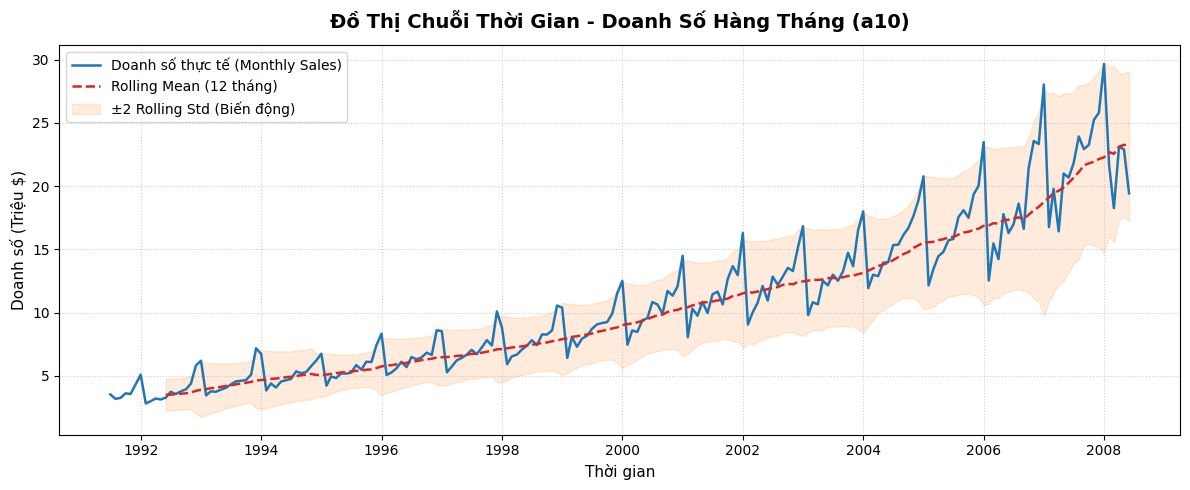

In [41]:
# 2. Vẽ đồ thị chuỗi thời gian (Time Series Plot)
plt.figure(figsize=(12, 5))

# Vẽ đường giá trị thực tế
plt.plot(df.index, df['value'], color='#1f77b4', linewidth=1.8, label='Doanh số thực tế (Monthly Sales)')

# Tính và vẽ đường Rolling Mean & Rolling Std (cửa sổ 12 tháng)
rolling_mean = df['value'].rolling(window=12).mean()
rolling_std = df['value'].rolling(window=12).std()

plt.plot(rolling_mean, color='#d62728', linestyle='--', linewidth=1.8, label='Rolling Mean (12 tháng)')
plt.fill_between(
    df.index, 
    rolling_mean - 2 * rolling_std, 
    rolling_mean + 2 * rolling_std, 
    color='#ff7f0e', alpha=0.15, 
    label='±2 Rolling Std (Biến động)'
)

# Tùy biến tiêu đề & định dạng trục
plt.title('Đồ Thị Chuỗi Thời Gian - Doanh Số Hàng Tháng (a10)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Thời gian', fontsize=11)
plt.ylabel('Doanh số (Triệu $)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()

# Lưu biểu đồ vào docs/images phục vụ báo cáo
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/01_ts_plot_a10.png', dpi=300)
plt.show()


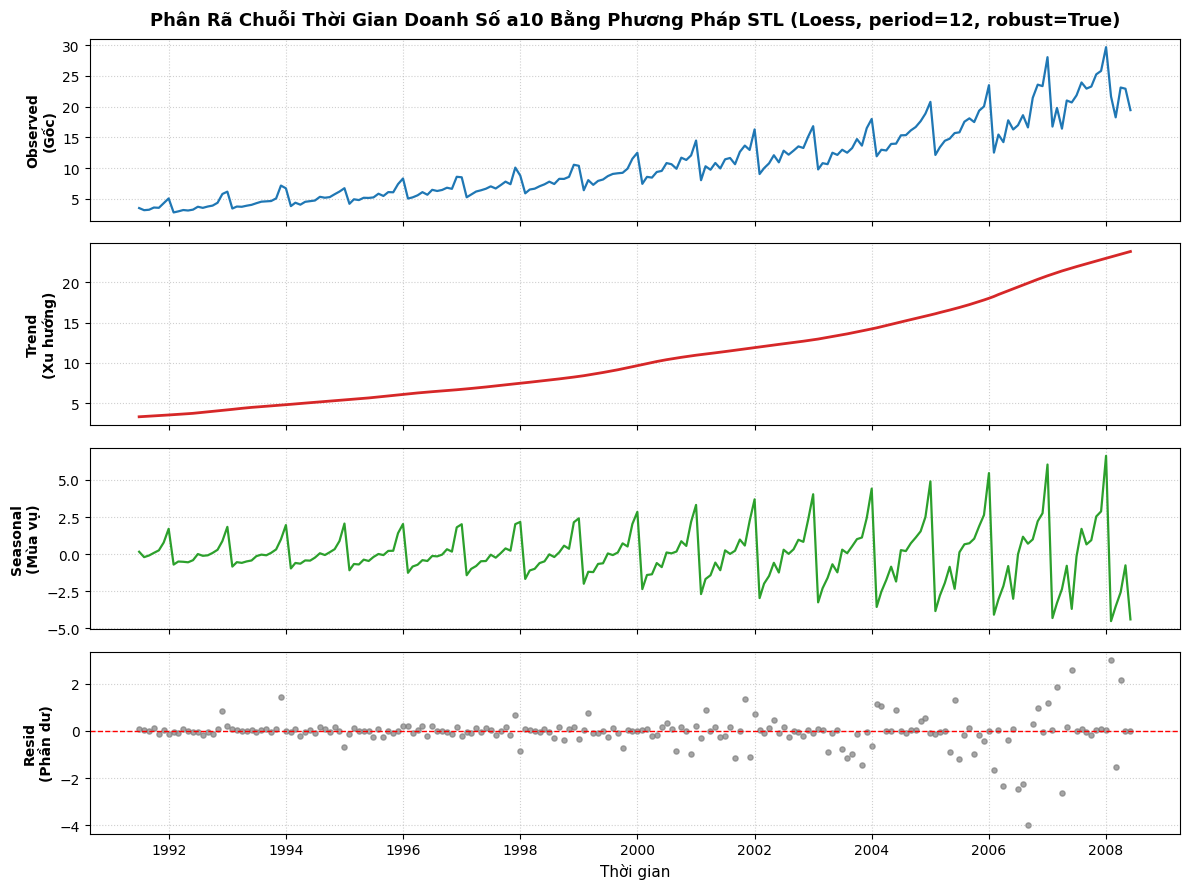

In [42]:
# 3. Phân rã chuỗi thời gian bằng phương pháp STL (Seasonal and Trend decomposition using Loess)
# STL là phương pháp hồi quy cục bộ (Loess) phi tham số hiện đại, cho phép ước lượng trọn vẹn (không mất dữ liệu ở hai đầu) và kháng ngoại lai (robust=True)
stl = STL(df['value'], period=12, robust=True)
res_stl = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

# 1. Observed (Chuỗi gốc)
axes[0].plot(res_stl.observed, color='#1f77b4', lw=1.6)
axes[0].set_ylabel('Observed\n(Gốc)', fontsize=10, fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].set_title('Phân Rã Chuỗi Thời Gian Doanh Số a10 Bằng Phương Pháp STL (Loess, period=12, robust=True)', fontsize=13, fontweight='bold', pad=10)

# 2. Trend (Xu hướng)
axes[1].plot(res_stl.trend, color='#d62728', lw=2)
axes[1].set_ylabel('Trend\n(Xu hướng)', fontsize=10, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)

# 3. Seasonal (Mùa vụ)
axes[2].plot(res_stl.seasonal, color='#2ca02c', lw=1.6)
axes[2].set_ylabel('Seasonal\n(Mùa vụ)', fontsize=10, fontweight='bold')
axes[2].grid(True, linestyle=':', alpha=0.6)

# 4. Residual (Phần dư)
axes[3].scatter(df.index, res_stl.resid, color='#7f7f7f', s=14, alpha=0.7)
axes[3].axhline(0.0, color='red', linestyle='--', lw=1)
axes[3].set_ylabel('Resid\n(Phần dư)', fontsize=10, fontweight='bold')
axes[3].set_xlabel('Thời gian', fontsize=11)
axes[3].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/01_decomposition_a10.png', dpi=300)
plt.show()


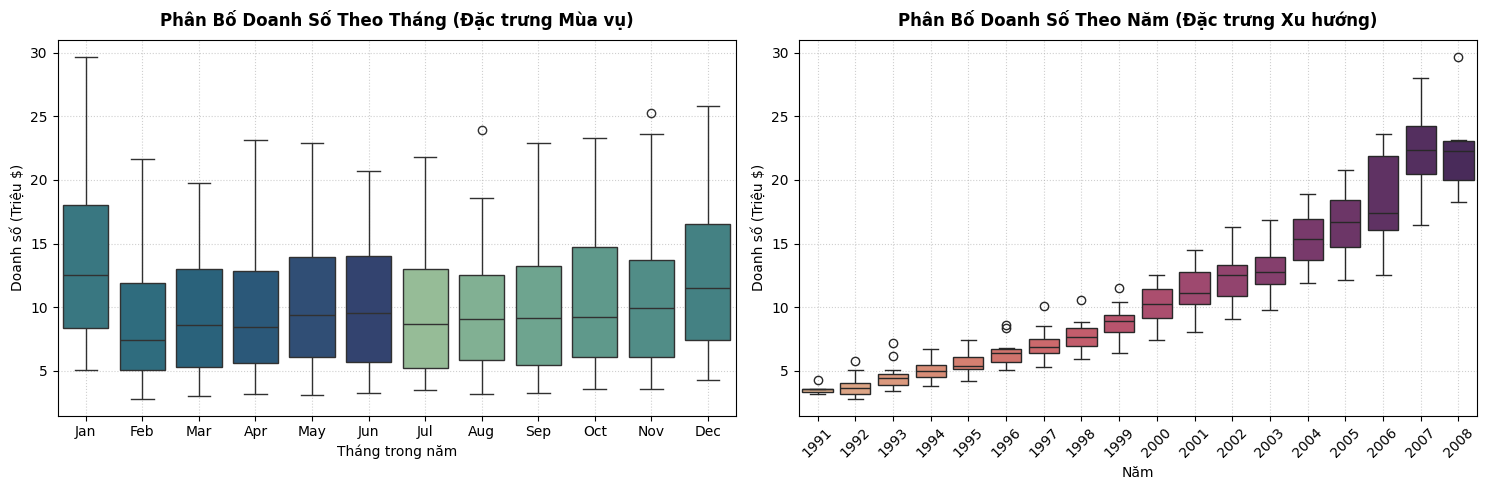

In [43]:
# 4. Khảo sát đặc trưng Mùa vụ & Xu hướng qua Boxplot đa chiều
df_box = df.copy()
df_box['Year'] = df_box.index.year
df_box['Month'] = df_box.index.strftime('%b')
months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Month-wise Boxplot (Khảo sát tính Mùa vụ nội năm)
sns.boxplot(
    data=df_box, 
    x='Month', 
    y='value', 
    order=months_order, 
    palette='crest', 
    hue='Month', 
    legend=False, 
    ax=axes[0]
)
axes[0].set_title('Phân Bố Doanh Số Theo Tháng (Đặc trưng Mùa vụ)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Tháng trong năm', fontsize=10)
axes[0].set_ylabel('Doanh số (Triệu $)', fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Year-wise Boxplot (Khảo sát Xu hướng dài hạn)
sns.boxplot(
    data=df_box, 
    x='Year', 
    y='value', 
    palette='flare', 
    hue='Year', 
    legend=False, 
    ax=axes[1]
)
axes[1].set_title('Phân Bố Doanh Số Theo Năm (Đặc trưng Xu hướng)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Năm', fontsize=10)
axes[1].set_ylabel('Doanh số (Triệu $)', fontsize=10)
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('../docs/images/01_boxplots_a10.png', dpi=300)
plt.show()


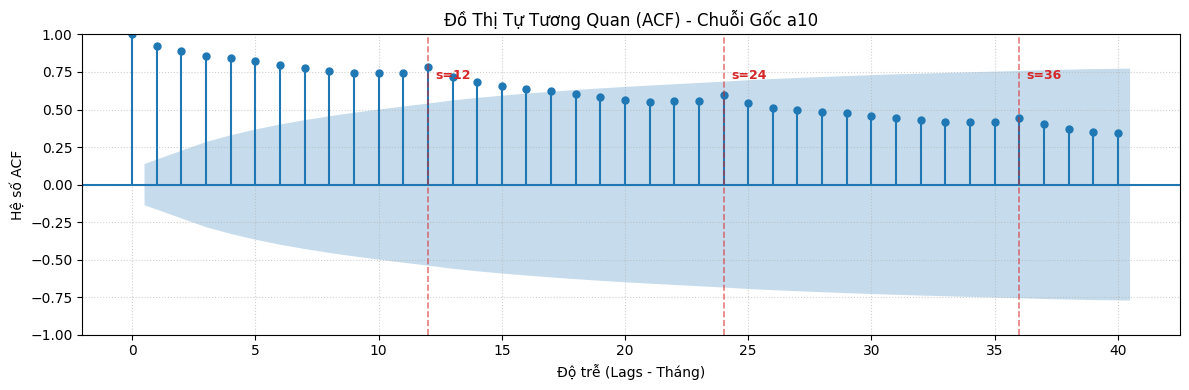

In [44]:
# 5. Phân tích Tự tương quan sơ bộ (ACF Plot của chuỗi gốc)
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df['value'], lags=40, ax=ax, alpha=0.05, title='Đồ Thị Tự Tương Quan (ACF) - Chuỗi Gốc a10')
ax.set_xlabel('Độ trễ (Lags - Tháng)', fontsize=10)
ax.set_ylabel('Hệ số ACF', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

# Đánh dấu các mốc lag mùa vụ chu kỳ 12 tháng
for lag in [12, 24, 36]:
    ax.axvline(x=lag, color='#d62728', linestyle='--', alpha=0.6, lw=1.2)
    ax.text(lag + 0.3, 0.7, f's={lag}', color='#d62728', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('../docs/images/01_acf_a10.png', dpi=300)
plt.show()


### 📝 Kết luận & Giải đáp các câu hỏi Bài 1 (EDA)

Dựa trên các phân tích và biểu đồ trực quan ở trên, ta có kết luận chi tiết cho 3 câu hỏi của Bài 1:

1. **Chuỗi có xu hướng không?**
   - **CÓ (Xu hướng tăng mạnh mẽ - Upward Trend):**
     - Đồ thị chuỗi thời gian gốc và đường **Rolling Mean (12 tháng)** đều dốc lên liên tục qua thời gian (từ ~3.5 triệu $ năm 1991 lên tới ~25-29 triệu $ năm 2008).
     - Thành phần **Trend** trong biểu đồ phân rã **STL (Loess)** là một đường cong trơn tăng đều đặn, không có giai đoạn suy thoái dài hạn.
     - Biểu đồ **Year-wise Boxplot** cho thấy trung vị và toàn bộ khoảng phân vị tịnh tiến đi lên qua từng năm mà không đổi chiều.

2. **Có dấu hiệu mùa vụ không?**
   - **CÓ (Tính mùa vụ rất rõ nét - Strong Seasonality với chu kỳ $s = 12$ tháng):**
     - Thành phần **Seasonal** bóc tách bằng **STL** lặp lại dạng sóng tuần hoàn với chu kỳ chính xác 12 tháng.
     - Biểu đồ **Month-wise Boxplot** chỉ rõ cấu trúc mùa vụ đặc thù: Doanh số **đạt đỉnh (peak) cao nhất vào tháng 1** hàng năm, sau đó **rơi xuống đáy vào tháng 2**, và tăng dần đều trở lại vào các tháng cuối năm (tháng 11 - 12).
     - Đồ thị **ACF chuỗi gốc** có các đỉnh nhô cao định kỳ tại các độ trễ mùa vụ $s = 12, 24, 36$.
     - *Ưu điểm STL:* Phương pháp STL sử dụng hồi quy cục bộ phi tuyến Loess với `robust=True` giúp bảo toàn toàn vẹn dữ liệu (không bị mất NaN ở 2 đầu như phương pháp bình quân trượt truyền thống) và kháng nhiễu ngoại lai rất tốt.

3. **Chuỗi có khả năng dừng không?**
   - **KHÔNG CÓ KHẢ NĂNG DỪNG (Non-stationary):**
     - **Vi phạm tính dừng về kỳ vọng:** Giá trị trung bình thay đổi theo thời gian ($\mathbb{E}[Y_t] \neq \text{const}$) do xu hướng tăng.
     - **Vi phạm tính dừng về phương sai:** Độ biến thiên và đường **Rolling Std** tăng dần theo thời gian ($\operatorname{Var}(Y_t) \neq \text{const}$).
     - **Hệ số ACF giảm rất chậm (Slow Decay):** Các giá trị ACF duy trì dương và cao qua hơn 40 lags (dấu hiệu chuỗi không dừng có trí nhớ dài).
   - $\rightarrow$ **Hệ quả:** Chuỗi cần được kiểm định chính thức bằng **ADF Test (Bài 2)** và cần áp dụng **sai phân (Differencing - Bài 3)** trước khi ước lượng mô hình ARIMA/SARIMA.